# Zürich's pulse over 24 hours: an animated GTFS timelapse
*#30DayMapChallenge*

Every dot is one **scheduled** vehicle (S-Bahn, tram, bus, boat, funicular), built from the official Swiss open timetable (GTFS), not live GPS.
The animation runs from **04:00 to 04:00** on one ordinary weekday and is exported as an **MP4**.

**Pipeline**
1. Download the Swiss national GTFS feed from opentransportdata.swiss
2. Find the trips running on the chosen day (plus the evening before and the night after, so the overnight network is right)
3. Keep only stop times inside the Zürich map frame
4. Download the tram, rail and street networks from OpenStreetMap and route every stop-to-stop hop along the real tracks and roads. The Swiss feed has no `shapes.txt`, so we build the shapes ourselves.
5. Interpolate each vehicle's position along its route for every frame
6. Render a glowing dark-mode map with route colours and encode it with ffmpeg

**First run:** roughly 10–20 minutes (about 155 MB download, a large `stop_times.txt` scan, OSM downloads, routing). Everything is cached in `data/`, so re-renders with different styling take a few minutes.

In [46]:
# Run once. If you're in a fresh environment, restart the kernel afterwards.
%pip install -q "osmnx>=2.0" pandas numpy matplotlib pyproj scipy tqdm requests imageio-ffmpeg pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\User\anaconda3\envs\myenv\python.exe -m pip install --upgrade pip


## 1 · Settings
Everything you might want to tweak is here.

In [48]:
from pathlib import Path
import zipfile, hashlib, logging, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from pyproj import Transformer
from scipy.spatial import cKDTree
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from tqdm.auto import tqdm

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)

# ---- What & when -------------------------------------------------------
CITY_NAME    = "Zürich"
SERVICE_DATE = "2026-11-25"   # an ordinary Wednesday. It must fall inside the feed's validity
                              # (timetable 2026 runs until 12 Dec 2026; after that use the 2027 feed).
                              # Pick a Friday for a richer night network (Zürich's night buses run Fri/Sat nights).
START_H, END_H = 4, 28        # 04:00 -> 04:00 next day (GTFS times can exceed 24:00)

# Swiss national GTFS (official, CC-style "open use, must provide the source")
GTFS_URL = "https://data.opentransportdata.swiss/dataset/timetable-2026-gtfs2020/permalink"

# ---- Map frame (lon/lat) ---------------------------------------------------
# (west, south, east, north). If it doesn't match the map panel's aspect ratio it gets stretched (never cropped).
DISPLAY_BBOX  = (8.455, 47.335, 8.625, 47.435)   # ≈ 13 km × 11.3 km, matches the map panel almost exactly
# The map sits in its own panel between a title band (top) and a chart band (bottom), so nothing
# on the map is hidden or dimmed under the text. Fractions of the video height:
TOP_BAND, BOTTOM_BAND = 0.17, 0.13
DATA_BUFFER_M = 2500          # also load stops/streets this far outside the frame

# ---- Route shapes ------------------------------------------------------
USE_OSM_ROUTING = True        # False = straight lines between stops (fast, but less pretty)

# ---- Video ------------------------------------------------------------------
FPS           = 30
VIDEO_SECONDS = 60            # 24 h in 60 s => one frame ≈ 48 s of timetable
WIDTH_PX, HEIGHT_PX = 1080, 1350   # 4:5 portrait works well on LinkedIn/Instagram. Use 1080x1920 for Reels/Shorts.
DPI           = 100
TRAIL_STEPS   = 5             # comet tail length (number of ghost dots)
TRAIL_DT_S    = 14            # seconds of timetable between ghost dots

# ---- Style --------------------------------------------------------------------
BG          = "#06080c"
WATER       = "#0c1824"
STREETS     = "#161b22"
TEXT        = "#e8edf2"
SUBTEXT     = "#8a96a3"
FONT        = ["Inter", "Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]
DOT_SIZE    = {"rail": 10, "tram": 8, "bus": 4.5, "ferry": 10, "funicular": 9, "gondola": 9}
DOT_SCALE   = 1.8             # multiply every dot (and its glow) by this
ROUTE_ALPHA = {"rail": 0.30, "tram": 0.26, "bus": 0.08, "ferry": 0.25, "funicular": 0.25, "gondola": 0.25}
ROUTE_LW    = {"rail": 0.45, "tram": 0.6, "bus": 0.5, "ferry": 0.6, "funicular": 0.6, "gondola": 0.6}
HIDE_STRAIGHT_OVER_M = 1500   # don't draw the faint line for straight-line fallbacks longer than this

# Fallback palettes, used only when the feed has no route_color for a route
FALLBACK = {
    "rail":      ["#ff4d6d", "#ff7b39", "#ffb703", "#ff5fa2", "#f94144"],
    "tram":      ["#4cc9f0", "#4895ef", "#72efdd", "#b5179e", "#f72585", "#7209b7",
                  "#3a86ff", "#06d6a0", "#ffd166", "#ef476f", "#8338ec", "#80ffdb"],
    "bus":       ["#cfe8ff", "#e9f1f7", "#bde0fe", "#d8e2dc", "#cdb4db"],
    "ferry":     ["#00bbf9"],
    "funicular": ["#f15bb5"],
    "gondola":   ["#f15bb5"],
}
# Small place labels on the map: (name, lon, lat, label position relative to the point: "right"/"left"/"center")
PLACE_LABELS = [
    ("Zürich HB",   8.5403, 47.3779, "right"),
    ("Hardbrücke",  8.5170, 47.3853, "left"),
    ("Altstetten",  8.4889, 47.3914, "left"),
    ("Oerlikon",    8.5446, 47.4115, "right"),
    ("Stadelhofen", 8.5486, 47.3667, "right"),
    ("Stettbach",   8.5960, 47.3973, "right"),
    ("Uetliberg",   8.4919, 47.3497, "right"),
]
WATER_LABELS = [("Zürichsee", 8.5560, 47.3440)]   # (name, lon, lat), written in italics on the water
LABEL_COLOR = "#aab4bf"

# Force colours for specific lines, keyed "mode:short_name", e.g. {"tram:4": "#3a86ff", "rail:S5": "#ff4d6d"}
ROUTE_COLOR_OVERRIDES = {}

DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
OUT_DIR  = Path("output"); OUT_DIR.mkdir(exist_ok=True)

TO_M  = Transformer.from_crs(4326, 2056, always_xy=True)   # lon/lat -> Swiss LV95 metres
TO_LL = Transformer.from_crs(2056, 4326, always_xy=True)   # Swiss LV95 metres -> lon/lat

## 2 · Map frame in metres
We work in the Swiss LV95 grid (EPSG:2056), so distances are real metres and the map isn't stretched.

In [50]:
# takes a bounding box in degrees and returns the same area as a box in metres
def bbox_to_m(b):
    xs, ys = TO_M.transform([b[0], b[2], b[0], b[2]], [b[1], b[1], b[3], b[3]])
    return min(xs), min(ys), max(xs), max(ys)

# unpack the box into the west edge (x min), south edge (y min), east edge (x max) and north edge (y max)
dx0, dy0, dx1, dy1 = bbox_to_m(DISPLAY_BBOX)
# shape of the map panel (width ÷ height), not the whole video
aspect = WIDTH_PX / (HEIGHT_PX * (1 - TOP_BAND - BOTTOM_BAND))
# define the box by its centre plus width and height
cx, cy, w, h = (dx0 + dx1) / 2, (dy0 + dy1) / 2, dx1 - dx0, dy1 - dy0
# fit the box to the panel's shape: grow width or height, never shrink (never crop)
if w / h < aspect: w = h * aspect
else:              h = w / aspect
VIEW = (cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2)          # what the camera sees
DATA = (VIEW[0] - DATA_BUFFER_M, VIEW[1] - DATA_BUFFER_M,
        VIEW[2] + DATA_BUFFER_M, VIEW[3] + DATA_BUFFER_M)        # VIEW plus a margin, so vehicles don't vanish at the edge
# convert DATA back to degrees, because the OSMnx download needs a box in degrees
lons, lats = TO_LL.transform([DATA[0], DATA[2], DATA[0], DATA[2]], [DATA[1], DATA[1], DATA[3], DATA[3]])
DATA_BBOX_LL = (min(lons), min(lats), max(lons), max(lats))      # (left, bottom, right, top) for osmnx
# print a check
print(f"View: {w/1000:.1f} km × {h/1000:.1f} km   |   data bbox (lon/lat): {np.round(DATA_BBOX_LL, 4)}")

View: 13.0 km × 11.4 km   |   data bbox (lon/lat): [ 8.4196 47.3102  8.6609 47.4597]


## 3 · Download the GTFS feed
If the automatic download fails (the portal sometimes changes its links), open
<https://opentransportdata.swiss/en/dataset/timetable-2026-gtfs2020>, download the latest `GTFS_FP2026_*.zip`, and save it as `data/gtfs_ch.zip`.

In [52]:
import requests

GTFS_ZIP = DATA_DIR / "gtfs_ch.zip"   # where the file goes
if not GTFS_ZIP.exists():             # download only if the file is not there yet
    tmp = GTFS_ZIP.with_suffix(".part")   # download to a temporary .part file first; rename only when complete
    with requests.get(GTFS_URL, stream=True, timeout=120, allow_redirects=True) as r:   # open the connection
        r.raise_for_status()   # if the server replied with an error such as 404 Not Found, stop now rather than saving an error page as if it were the file
        total = int(r.headers.get("content-length", 0)) or None   # file size from the server (None if unknown), for the progress bar
        with open(tmp, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc="GTFS") as bar:   # open the file (binary mode) and start the progress bar
            for chunk in r.iter_content(1 << 20):   # file arrives 1 MB at a time
                f.write(chunk); bar.update(len(chunk))   # save each chunk and move the bar forward
    if not zipfile.is_zipfile(tmp):   # not a zip (e.g. an error page)? delete it and stop with a clear message
        tmp.unlink()
        raise RuntimeError("The download wasn't a zip file. Please download it manually (see the note above) "
                           "and save it as data/gtfs_ch.zip")
    tmp.rename(GTFS_ZIP)   # download complete and valid: give it its real name

# open the zip and list its contents
z = zipfile.ZipFile(GTFS_ZIP)
NAMES = set(z.namelist())
print(sorted(NAMES))

# helper for reading files from the zip
def read_txt(name, **kw):
    with z.open(name) as f:
        return pd.read_csv(f, dtype=str, keep_default_na=False, **kw)
# dtype=str reads every column as text to keep leading zeros in IDs; numbers are converted deliberately later
# keep_default_na=False keeps empty cells as "", not NaN ("not a number")
# **kw passes any extra options through to read_csv (e.g. usecols to load only some columns)

# show who published the feed and the dates it covers (feed_info.txt is optional)
if "feed_info.txt" in NAMES:
    display(read_txt("feed_info.txt"))

['agency.txt', 'calendar.txt', 'calendar_dates.txt', 'feed_info.txt', 'frequencies.txt', 'routes.txt', 'stop_times.txt', 'stops.txt', 'transfers.txt', 'trips.txt']


,feed_publisher_name,feed_publisher_url,feed_lang,feed_start_date,feed_end_date,feed_version
0,SBB,https://sbb.ch,DE,20251214,20261212,20261118


### What's inside the GTFS zip

A GTFS feed is a zip of plain CSV text files. Each file is one table, and the tables link to each other through IDs.

| File | What it holds | Used here? |
|---|---|---|
| `stops.txt` | every stop and station, with name and coordinates | ✅ stop positions |
| `routes.txt` | every line (tram 4, S5, bus 33…), its type and optional colour | ✅ mode and colour |
| `trips.txt` | each single run of a line, e.g. "tram 4 leaving at 07:12" | ✅ links runs to lines and calendars |
| `stop_times.txt` | when each trip arrives at and leaves each stop (≈ 2 GB unzipped) | ✅ the heart of the animation |
| `calendar.txt` | weekly patterns: "runs Mon–Fri between two dates" | ✅ which trips run on our date |
| `calendar_dates.txt` | exceptions: "not on 25 Dec", "extra on 1 Aug" | ✅ holidays and special days |
| `feed_info.txt` | who published the feed and the dates it covers | ℹ️ shown as a check |
| `agency.txt` | the operators (SBB, VBZ, ZVV…) | ❌ |
| `transfers.txt` | connection times between lines | ❌ (for journey planners) |
| `frequencies.txt` | "every N minutes from … to …" instead of listing each trip | ❌ (check it's empty: `len(read_txt("frequencies.txt"))`) |

How they link:

```
routes ──route_id──► trips ──trip_id──► stop_times ──stop_id──► stops
                       │
                   service_id
                       ▼
             calendar / calendar_dates
```

**Missing:** `shapes.txt`, the optional file with the exact path vehicles take between stops. That's why this notebook builds route shapes from OpenStreetMap instead.

### Reading `feed_info.txt`

| Column | Value | Meaning |
|---|---|---|
| `feed_publisher_name` | SBB | The publisher. SBB (Swiss Federal Railways) compiles the national timetable for all Swiss operators, so this one feed includes trams, buses and boats too, not only trains. |
| `feed_publisher_url` | https://sbb.ch | The publisher's website. |
| `feed_lang` | DE | Language of the text in the feed (German), e.g. stop names like *Zürich HB* and *Bahnhofplatz*. |
| `feed_start_date` | 20251214 | First day the timetable covers: **14 Dec 2025**. |
| `feed_end_date` | 20261212 | Last day it covers: **12 Dec 2026**. Swiss timetables change every December, so each feed covers one "timetable year". |
| `feed_version` | 20261118 | Which edition of the feed this is. It looks like the build date, **18 Nov 2026**. The feed is republished regularly with corrections, so a newer download can differ slightly. |

**Why this matters:** `SERVICE_DATE` must fall between `feed_start_date` and `feed_end_date`. Pick a date after 12 Dec 2026 and no trips will match. For that you'd need the 2027 feed.

## 4 · Stops, routes and the service day
GTFS days can run past midnight (for example `25:30:00`), so we load trips for **the day before, the day itself and the day after**, shift their clocks, and keep whatever falls inside our 04:00→04:00 window.

In [55]:
# =============================================================================
# SECTION 4 · Stops, routes and the service day
# Goal: find (1) which stops are in our area, (2) what kind of vehicle each line is,
#       and (3) which trips run on our chosen day (plus the days either side).
# =============================================================================

# --- 1. STOPS: load all Swiss stops, convert to metres, keep only those inside the DATA box

# Read only the 4 columns we need. usecols takes a function, so columns missing
# from the feed are skipped rather than causing an error.
stops = read_txt("stops.txt", usecols=lambda c: c in {"stop_id", "stop_name", "stop_lat", "stop_lon"})

# Coordinates were read as text (dtype=str). Convert them to numbers now.
# errors="coerce" turns anything unreadable (empty, garbage) into NaN instead of crashing.
stops["lat"] = pd.to_numeric(stops.stop_lat, errors="coerce")
stops["lon"] = pd.to_numeric(stops.stop_lon, errors="coerce")

# Drop stops without valid coordinates: we can't place them on a map.
stops = stops.dropna(subset=["lat", "lon"])

# Convert every stop from degrees to Swiss metres (LV95) in one call.
# .values passes plain NumPy arrays, which pyproj handles fastest.
stops["x"], stops["y"] = TO_M.transform(stops.lon.values, stops.lat.values)

# True/False for each stop: is it inside the DATA box (view + 2.5 km margin)?
# between(a, b) checks a <= value <= b. Use & (not "and") to combine whole columns.
inside = stops.x.between(DATA[0], DATA[2]) & stops.y.between(DATA[1], DATA[3])

# Keep only the stops inside, and use stop_id as the row label,
# so we can look a stop up directly later: stops.loc["8503000"]
stops = stops[inside].set_index("stop_id")

# The wanted stop IDs as a pandas Index: very fast for "is this ID in the list?"
# checks, which Section 5 does millions of times.
STOP_IDS = pd.Index(stops.index)

# :, adds thousands separators, e.g. 1,234
print(f"{len(stops):,} stops inside the data frame")


# --- 2. ROUTES: what kind of vehicle is each line?

routes = read_txt("routes.txt")

# These three columns are optional in GTFS. If the feed lacks one, add it empty,
# so later code can always rely on it existing.
for c in ["route_short_name", "route_long_name", "route_color"]:
    if c not in routes: routes[c] = ""

def base_mode(rt):
    # Turn a GTFS route_type number into one of six simple groups.
    # Handles both the basic types (0-12) and the extended types (100-1700) the Swiss feed uses.
    try: rt = int(rt)                       # route_type was read as text; make it a number
    except ValueError: return "bus"         # missing or weird value: treat as bus rather than crash
    if rt == 0 or 900 <= rt < 1000:                                return "tram"       # 0 = tram; 900s = tram services
    if rt in (1, 2, 12) or 100 <= rt < 200 or 400 <= rt < 500:     return "rail"       # 1 metro, 2 rail, 12 monorail; 100s railway; 400s urban rail
    if rt == 4 or 1000 <= rt < 1100 or 1200 <= rt < 1300:          return "ferry"      # 4 = ferry; 1000s water transport; 1200s ferry
    if rt == 7 or 1400 <= rt < 1500:                               return "funicular"  # 7 = funicular; 1400s funicular
    if rt in (5, 6) or 1300 <= rt < 1400:                          return "gondola"    # 5 = cable tram, 6 = aerial lift; 1300s aerial lifts
    return "bus"   # everything else: 3 bus, 11 trolleybus, 200s coach, 700s bus, 800s trolleybus, 1100s air, 1500s taxi, 1700s misc

# Run base_mode on every line and store the result in a new "mode" column.
routes["mode"] = routes.route_type.map(base_mode)

# Display name per line: the short name ("4", "S5") if there is one, otherwise the long name.
# np.where(condition, A, B) = for each row, A if condition is true, else B.
# This "name" is what ROUTE_COLOR_OVERRIDES keys like "tram:4" refer to.
routes["name"] = np.where(routes.route_short_name != "", routes.route_short_name, routes.route_long_name)


# --- 3. CALENDARS: which services run on which day?
# Trips don't list dates themselves. Each trip has a service_id, a label for a calendar
# pattern, and the calendar files say on which days each label is active.

# calendar.txt       = weekly patterns, e.g. "Mon-Fri between two dates"
# calendar_dates.txt = exceptions, e.g. "not on 25 Dec" or "extra on 1 Aug"
# Both are optional, so use None when one is missing.
cal = read_txt("calendar.txt") if "calendar.txt" in NAMES else None
cd  = read_txt("calendar_dates.txt", usecols=["service_id", "date", "exception_type"]) \
      if "calendar_dates.txt" in NAMES else None      # the backslash continues the line

def services_on(day):
    """Return the set of service_ids that run on the given day (a pandas Timestamp)."""
    # GTFS date format, e.g. "20261125", and the weekday name, e.g. "wednesday"
    # (which is also the name of a column in calendar.txt).
    ymd, wd = day.strftime("%Y%m%d"), day.day_name().lower()
    on = set()                                 # start with an empty set of running services

    # A) Weekly pattern: the service is on if the date is within its start/end dates
    #    AND the weekday column (e.g. "wednesday") is "1".
    #    Dates are compared as text. That works because YYYYMMDD sorts in date order.
    if cal is not None:
        m = (cal.start_date <= ymd) & (cal.end_date >= ymd) & (cal[wd] == "1")
        on |= set(cal.service_id[m])           # |= adds these services to the set (union)

    # B) Exceptions for this exact date.
    if cd is not None:
        today = cd[cd.date == ymd]             # only the exceptions for this date
        on |= set(today.service_id[today.exception_type == "1"])   # type 1 = service ADDED on this date
        on -= set(today.service_id[today.exception_type == "2"])   # type 2 = service REMOVED on this date
    return on


# --- 4. TRIPS: collect trips from three service days
# GTFS service days run past midnight (a bus at "25:30:00" belongs to the previous day).
# Our animation runs 04:00 Wednesday -> 04:00 Thursday, so trips from three service days can be on screen:
#   -1 = Tuesday   (a trip at e.g. 28:10 is really 04:10 Wednesday: rare, but possible)
#    0 = Wednesday (the main day: almost everything)
#   +1 = Thursday  (a trip at e.g. 03:30 Thursday falls before our 04:00 end)
# Section 6 shifts each trip's clock by its day_offset x 24 h and keeps only 04:00-28:00.

D = pd.Timestamp(SERVICE_DATE)                 # our chosen day as a date object

# Only the columns we need: which line, which calendar, which trip.
trips = read_txt("trips.txt", usecols=["route_id", "service_id", "trip_id"])

trip_days = []                                 # one table per service day, combined below
for off in (-1, 0, 1):
    svc = services_on(D + pd.Timedelta(days=off))   # services running on that day
    # Keep trips whose service runs that day, and record which day it was.
    # A trip that runs on several of the three days appears once per day, which is intended.
    t = trips[trips.service_id.isin(svc)][["trip_id", "route_id"]].assign(day_offset=off)
    trip_days.append(t)
    print(f"{(D + pd.Timedelta(days=off)).date()}: {len(t):,} trips run nationwide")   # whole of Switzerland

# Stack the three tables into one. ignore_index renumbers the rows 0, 1, 2, ...
trip_days = pd.concat(trip_days, ignore_index=True)

# Safety check: no trips at all on the main day almost always means the date
# is outside the feed's validity period (see feed_info.txt), so stop with a clear message.
if (trip_days.day_offset == 0).sum() == 0:
    raise ValueError(f"No trips on {SERVICE_DATE}. Is the date inside the feed's validity period?")

# Every trip ID that might appear, as a fast-lookup Index for Section 5.
# Section 5 combines this with STOP_IDS to narrow Switzerland down to Zürich.
WANTED_TRIPS = pd.Index(trip_days.trip_id.unique())

4,154 stops inside the data frame
2026-11-24: 191,730 trips run nationwide
2026-11-25: 191,303 trips run nationwide
2026-11-26: 191,843 trips run nationwide


## 5 · Scan `stop_times.txt`
The national file is about 2 GB unzipped, so we stream it in chunks and keep only rows that are (a) inside our frame and (b) on a trip that runs in our window. This takes a few minutes, and the result is cached. This section is meant to find when each vehicle is at each stop

In [57]:
# =============================================================================
# SECTION 5 · Scan stop_times.txt
# Goal: from the ~2 GB national file, keep only the rows for stops in our area
#       on trips that run on our three service days. Convert times to seconds,
#       and cache the result so this slow step only runs once.
# =============================================================================

# --- 1. CACHE FILE NAME
# The name includes everything that changes the result:
#   SERVICE_DATE        -> a different day means different trips
#   hash(DATA_BBOX_LL)  -> a fingerprint of the map area; change the box and the name changes
# abs() makes the number positive; % 10**8 keeps only the last 8 digits so the name stays short.
# NOTE: the feed version is NOT in the name. After downloading a newer GTFS zip,
#       delete the stop_times_*.parquet files in data/ so they're rebuilt.
ST_CACHE = DATA_DIR / f"stop_times_{SERVICE_DATE}_{abs(hash(DATA_BBOX_LL)) % 10**8}.parquet"


# --- 2. HELPER: turn "HH:MM:SS" text into seconds since midnight of the service day
def hms_to_sec(s):
    # Regular expression:  ^(\d+):(\d{2}):(\d{2})$
    #   ^ ... $   the whole text must match (start to end)
    #   (\d+)     hours: one or more digits, so "7", "07" and "25" all work
    #   (\d{2})   minutes, then seconds: exactly two digits each
    # The ( ) brackets capture each part into its own column: 0 = hours, 1 = minutes, 2 = seconds.
    # strip() removes stray spaces; empty or malformed times don't match and become NaN.
    p = s.str.strip().str.extract(r"^(\d+):(\d{2}):(\d{2})$").astype(float)
    # e.g. "07:13:30" -> 7*3600 + 13*60 + 30 = 26010
    #      "25:30:00" -> 91800 (01:30 the next morning, still on this service day's clock)
    return p[0] * 3600 + p[1] * 60 + p[2]


# --- 3. USE THE CACHE if this date + area was scanned before
if ST_CACHE.exists():
    st = pd.read_parquet(ST_CACHE)            # Parquet: compact binary table, loads in about a second

# --- 4. OTHERWISE, SCAN THE BIG FILE IN CHUNKS
else:
    parts = []                                # matching pieces from each chunk, combined at the end
    cols = ["trip_id", "arrival_time", "departure_time", "stop_id", "stop_sequence"]   # only the 5 columns we need

    with z.open("stop_times.txt") as f:      # read straight from inside the zip (no unzipping to disk)
        # chunksize=2_000_000 -> read_csv hands over 2 million rows at a time, so memory stays small.
        # (Underscores in numbers are just for readability.)
        # dtype=str / keep_default_na=False -> keep IDs as text, as in Section 3.
        reader = pd.read_csv(f, dtype=str, usecols=cols, chunksize=2_000_000, keep_default_na=False)

        for chunk in tqdm(reader, desc="stop_times chunks (2M rows each)"):   # progress bar: one step per chunk
            # Keep a row only if BOTH:
            #   - its stop is inside our area     (STOP_IDS, from Section 4)
            #   - its trip runs on our 3 days     (WANTED_TRIPS, from Section 4)
            # This is where Switzerland narrows down to Zürich.
            m = chunk.stop_id.isin(STOP_IDS) & chunk.trip_id.isin(WANTED_TRIPS)
            if m.any():                       # any matches in this chunk?
                parts.append(chunk[m])        # keep only the matching rows; the rest is discarded

    # --- 5. COMBINE AND CLEAN
    st = pd.concat(parts, ignore_index=True)  # stack the kept pieces into one table ("st" = stop times)

    # Convert both time columns from text to seconds.
    st["arr"] = hms_to_sec(st.arrival_time)
    st["dep"] = hms_to_sec(st.departure_time)

    # GTFS allows one of the two times to be missing at a stop:
    # fill a missing arrival with the departure, and vice versa.
    st["arr"] = st.arr.fillna(st.dep); st["dep"] = st.dep.fillna(st.arr)

    # Stop order as numbers. As text, "10" would sort before "2" and scramble the trip.
    st["seq"] = st.stop_sequence.astype(int)

    # Keep only the columns used later, and drop rows that still have no time
    # (stops without times can't be placed; the vehicle goes straight between the timed stops around them).
    st = st[["trip_id", "stop_id", "seq", "arr", "dep"]].dropna()

    # --- 6. SAVE THE CACHE
    # Writing Parquet needs the pyarrow package. If it's missing, skip caching
    # rather than stop the notebook: we lose speed next time, not results.
    try:
        st.to_parquet(ST_CACHE)
    except Exception as e:
        print("(not cached:", e, ")")

# --- 7. REPORT: how many rows survived (typically a few hundred thousand out of tens of millions)
print(f"{len(st):,} stop-time rows inside the frame")

311,104 stop-time rows inside the frame


## 6 · Turn stop times into movement segments
Each vehicle is either **moving** between two consecutive stops or **dwelling** at a stop. Each segment is a time interval plus a geometry.

In [59]:
# =============================================================================
# SECTION 6 · Turn stop times into movement segments
# Goal: a vehicle is always either MOVING between two stops or DWELLING (waiting) at one.
#       Turn the stop times into a table of these intervals ("segments"):
#       from_stop, to_stop, start time t0, end time t1, and whether it's a dwell.
# =============================================================================

# --- 1. ATTACH THE SERVICE DAY AND PUT EVERY RUN ON WEDNESDAY'S CLOCK
# merge = join on trip_id. A trip running on several of our 3 days is copied once per day,
# which is correct: each copy is a separate vehicle run. This also attaches route_id.
s = st.merge(trip_days, on="trip_id")

# Shift times by whole days (86,400 s) so all runs share one timeline (seconds from Wednesday midnight):
#   Tuesday (-1)  28:10 -> 04:10 Wednesday      Thursday (+1) 03:30 -> 27:30 on Wednesday's clock
s["arr"] += s.day_offset * 86400
s["dep"] += s.day_offset * 86400

# trip_id is no longer unique (the same trip can appear for 3 days), so give each run its own key,
# e.g. "T123|0". astype(str) turns the number into text so it can be joined with +.
s["key"] = s.trip_id + "|" + s.day_offset.astype(str)

# Sort by run, then by stop order, so each run's stops are together and in sequence.
# reset_index(drop=True) renumbers the rows 0, 1, 2, ... after sorting.
s = s.sort_values(["key", "seq"]).reset_index(drop=True)


# --- 2. PAIR EACH STOP WITH THE NEXT ONE
# shift(-1) moves values up one row, so each row can see the NEXT stop and its arrival time.
# groupby("key") keeps this within each run: the last stop of a run gets NaN ("no next stop")
# instead of being paired with the first stop of an unrelated trip.
# sort=False: the table is already sorted, so skip re-sorting.
nxt = s.groupby("key", sort=False)[["stop_id", "arr"]].shift(-1)


# --- 3. MOVING SEGMENTS: leave this stop -> arrive at the next
# This builds a new table from columns. Each row is "leave this stop, arrive at the next":
move = pd.DataFrame({
    "key": s.key, "route_id": s.route_id,
    "from_stop": s.stop_id, "to_stop": nxt.stop_id,   # this stop -> next stop
    "t0": s.dep, "t1": nxt.arr,                       # DEPART here -> ARRIVE there (waiting time is handled in step 4)
}).dropna(subset=["to_stop"])                         # drop each run's last stop (it has no next stop)

# Keep only segments that take some time. With minute-rounded times, two stops can share
# the same minute (t1 == t0); a zero-length interval can't be shown and would divide by zero later.
move = move[move.t1 > move.t0]
move["dwell"] = False                                 # label: moving


# --- 4. DWELL SEGMENTS: waiting at a stop (departure later than arrival)
# Without these, a vehicle would vanish while waiting, e.g. a train standing at HB for 3 minutes.
dwell = s[s.dep > s.arr]
dwell = pd.DataFrame({"key": dwell.key, "route_id": dwell.route_id,
                      "from_stop": dwell.stop_id, "to_stop": dwell.stop_id,   # same stop: the dot stays still
                      "t0": dwell.arr, "t1": dwell.dep, "dwell": True})       # from arrival to departure


# --- 5. COMBINE AND KEEP WHAT OVERLAPS THE 04:00 -> 04:00 WINDOW
seg = pd.concat([move, dwell], ignore_index=True)    # same columns, so they stack into one table
# Keep segments that end after 04:00 AND start before 28:00 (overlap, not "fully inside"):
# a train running 03:58-04:03 should appear mid-journey when the animation starts.
seg = seg[(seg.t1 > START_H * 3600) & (seg.t0 < END_H * 3600)]


# --- 6. DROP "TELEPORTS"
# Section 5 kept only stops inside our area. A train that leaves the area and comes back
# (e.g. HB -> Winterthur -> HB) now has its last stop before leaving and first stop after
# returning looking consecutive, and would jump straight across the map.
# Real hops between neighbouring stops are never 12 km, so drop anything longer.
# (HB -> Flughafen, 8 km non-stop, is real: that's why the limit isn't lower.)
fx, fy = stops.loc[seg.from_stop, ["x", "y"]].to_numpy().T   # start stop coordinates (metres); .T = transpose
tx, ty = stops.loc[seg.to_stop,   ["x", "y"]].to_numpy().T   # end stop coordinates
seg["straight_m"] = np.hypot(tx - fx, ty - fy)               # Pythagoras: straight-line distance in metres
seg = seg[seg.straight_m < 12_000]
# When a vehicle leaves the map and comes back later, deleting the stops outside the map makes its last stop before leaving look directly connected to its first stop after returning
# Without the 12 km check, it would draw a fake straight-line jump across the city.

# --- 7. ATTACH EACH LINE'S MODE, NAME AND COLOUR (from Section 4)
# how="left" keeps every segment even if its route_id isn't in routes (the default would drop it).
seg = seg.merge(routes[["route_id", "mode", "name", "route_color"]], on="route_id", how="left")
# Safe defaults for any line that wasn't found, so later steps never meet a missing value.
seg["mode"] = seg["mode"].fillna("bus")
seg["name"] = seg["name"].fillna(""); seg["route_color"] = seg["route_color"].fillna("")


# --- 8. REPORT (sanity check: if trams showed 0, something upstream is wrong)
print(f"{len(seg):,} segments  |  {seg.key.nunique():,} vehicle trips")      # nunique = number of distinct runs
print(seg.drop_duplicates("key")["mode"].value_counts().to_string())         # runs per mode (one row per run)

317,478 segments  |  20,939 vehicle trips
mode
bus          12920
tram          5359
rail          1740
funicular      902
ferry           18


## 7 · Real route shapes from OpenStreetMap
Three networks are downloaded once and cached as GraphML:
- **tram**: `railway=tram|light_rail`
- **rail**: `railway=rail|light_rail|narrow_gauge|subway`
- **bus**: drivable roads plus bus-only roads (`highway=busway`, service roads)

Boats, funiculars and gondolas just use straight lines, which is what they look like anyway.

In [61]:
# =============================================================================
# SECTION 7 · Real route shapes from OpenStreetMap
# Goal: download the tram, rail and road networks and turn each into a graph
#       (points + connections) that Section 8 can route along quickly.
# =============================================================================
import osmnx as ox
ox.settings.use_cache = True        # OSMnx also caches raw downloads, so repeat requests skip the internet
ox.settings.log_console = False     # keep OSMnx quiet

# --- 1. WHICH OSM WAYS TO DOWNLOAD (Overpass filter syntax)
# ["tag"~"^(a|b)$"]  = the tag's value must be exactly a or b   (| = or, ^...$ = whole value)
# ["area"!~"yes"]    = and NOT tagged area=yes (squares/plazas drawn as shapes, not drivable lines)
ROAD = ("motorway|motorway_link|trunk|trunk_link|primary|primary_link|secondary|secondary_link|"
        "tertiary|tertiary_link|unclassified|residential|living_street|service|busway|road")
OSM_FILTERS = {
    "tram": '["railway"~"^(tram|light_rail)$"]',                 # tram tracks (+ light rail, e.g. Forchbahn, Glattalbahn)
    "rail": '["railway"~"^(rail|light_rail|narrow_gauge|subway)$"]',  # train tracks, incl. narrow gauge (Uetliberg)
    "bus":  f'["highway"~"^({ROAD})$"]["area"!~"yes"]',          # all drivable roads + bus-only (busway) + service roads
}
# Which network each mode routes on. Modes not listed (ferry, funicular, gondola) use straight lines.
ROUTED_MODES = {"tram": "tram", "rail": "rail", "bus": "bus"}
MIN_COMPONENT_NODES = 25   # network fragments smaller than this are dropped (see step 4a)
DENSIFY_M = 25             # one routing point every 25 m along every track/road (see step 4c)


# --- 2. DOWNLOAD A NETWORK ONCE, THEN LOAD IT FROM THE CACHE
def load_graph(kind):
    # Same caching pattern as Section 5: the file name includes a fingerprint of the area.
    path = DATA_DIR / f"osm_{kind}_{abs(hash(DATA_BBOX_LL)) % 10**8}.graphml"   # GraphML = standard graph file format
    if path.exists():
        return ox.load_graphml(path)
    print(f"Downloading OSM {kind} network…")
    G = ox.graph_from_bbox(DATA_BBOX_LL,                  # the DATA box in degrees (left, bottom, right, top)
                           custom_filter=OSM_FILTERS[kind],
                           simplify=True,                 # keep only junctions/ends as nodes; bends are stored as each edge's geometry
                           retain_all=True,               # keep every separate piece, not just the biggest
                           truncate_by_edge=True)         # keep roads crossing the box edge
    ox.save_graphml(G, path)
    return G


# --- 3. THE NETWORK: a routing-ready version of the OSM graph
class Network:
    # Builds:
    #   self.xy    every routing point's position in metres
    #   self.csr   the connections between points (sparse matrix) for fast shortest paths
    #   self.tree  a KD-tree for fast "nearest point to this stop" lookups
    #   self.lines each road/track as a polyline (used to draw the street background)
    #   self.km    total length, for the printout
    #
    # Why densify: a simplified OSM graph only has nodes at junctions. On a long stretch of track
    # (a tram line between junctions, an underground station like Zürich Flughafen) the nearest
    # node can be hundreds of metres from the stop, so the stop can't be snapped and the hop
    # falls back to a straight line. With a point every 25 m, every stop sits right on its track.
    def __init__(self, G, directed):

        # --- 4a. Drop tiny disconnected fragments (a lone siding, a platform cut off in OSM).
        # A connected component = a group of nodes all reachable from each other.
        # "Weakly" = ignore one-way direction when checking. Keep every piece with >= 25 nodes,
        # so real separate networks survive (e.g. SZU lines S4/S10, not joined to SBB tracks here).
        import networkx as nx
        keep = set().union(*[c for c in nx.weakly_connected_components(G) if len(c) >= MIN_COMPONENT_NODES])
        G = G.subgraph(keep).copy()

        # Give every OSM node a simple number 0, 1, 2, ... and get its position (degrees, then metres).
        nodes = list(G.nodes)
        idx = {n: i for i, n in enumerate(nodes)}          # OSM node ID -> our number
        lon = np.array([G.nodes[n]["x"] for n in nodes], float)
        lat = np.array([G.nodes[n]["y"] for n in nodes], float)
        nX, nY = TO_M.transform(lon, lat)

        # --- 4b. One shape per pair of nodes, plus which directions are allowed.
        # OSMnx stores each road once per direction; collapse them into one record per pair (a, b), a < b:
        #   [length, shape in lon/lat oriented a -> b, a->b allowed?, b->a allowed?]
        geo = {}
        for u, v, d in G.edges(data=True):
            i, j = idx[u], idx[v]
            if i == j: continue                            # skip loops that start and end at the same node
            # The edge's exact shape, or a straight line if OSM gave none.
            c = np.asarray(d["geometry"].coords) if "geometry" in d else np.array([[lon[i], lat[i]], [lon[j], lat[j]]])
            # Make sure the shape runs from u to v (some are stored backwards); [::-1] = reversed.
            if np.hypot(*(c[0] - (lon[i], lat[i]))) > np.hypot(*(c[-1] - (lon[i], lat[i]))):
                c = c[::-1]
            a, b = (i, j) if i < j else (j, i)             # always store the pair smaller-number-first
            if i > j: c = c[::-1]                          # ...and orient the shape a -> b to match
            L = float(d.get("length", 0)) or 1.0          # edge length in metres (OSMnx provides it)
            rec = geo.setdefault((a, b), [L, c, False, False])   # get the record, or create it
            if L < rec[0]: rec[0], rec[1] = L, c           # keep the shortest shape between the two nodes
            # Buses (directed=True) follow one-way streets; trams/trains may go both ways.
            if i < j or not directed: rec[2] = True        # a -> b allowed
            if i > j or not directed: rec[3] = True        # b -> a allowed

        # Convert ALL shapes to metres in one call (much faster than one call per shape):
        keys = list(geo)
        coords = [geo[k][1] for k in keys]
        allc = np.vstack(coords)                           # stack every shape into one big array
        X, Y = TO_M.transform(allc[:, 0], allc[:, 1])
        cuts = np.cumsum([len(c) for c in coords])[:-1]    # where each shape starts, to split them apart again

        # --- 4c. Densify: chop every shape into pieces of at most 25 m.
        xy_list, rows, cols, ws, self.lines = [np.c_[nX, nY]], [], [], [], []   # first points = the OSM nodes
        n_next = len(nodes)                                # IDs for new points continue after the OSM nodes
        for (a, b), x, y in zip(keys, np.split(X, cuts), np.split(Y, cuts)):
            line = np.c_[x, y]                             # this shape in metres
            line[0], line[-1] = (nX[a], nY[a]), (nX[b], nY[b])   # pin its ends exactly onto the two nodes
            seglen = np.hypot(*np.diff(line, axis=0).T)    # length of each straight piece of the shape
            pts = [line[:1]]
            for p0, p1, L in zip(line[:-1], line[1:], seglen):
                n = int(L // DENSIFY_M)                    # e.g. a 110 m piece gets 110 // 25 = 4 extra points
                if n:
                    # Points at fractions 1/(n+1), 2/(n+1), ... of the way from p0 to p1 (linear interpolation).
                    pts.append(p0 + (p1 - p0) * (np.arange(1, n + 1) / (n + 1))[:, None])
                pts.append(p1[None])
            pts = np.vstack(pts)
            self.lines.append(pts)                         # keep the full shape for drawing streets later
            inner = len(pts) - 2                           # new points between the two end nodes
            ids = np.r_[a, np.arange(n_next, n_next + inner), b]   # IDs along the shape: a, new..., b
            if inner:
                xy_list.append(pts[1:-1]); n_next += inner
            w = np.maximum(np.hypot(*np.diff(pts, axis=0).T), 0.01)   # each small step's length (never exactly 0)
            # Connect each consecutive pair of points: ids[:-1] -> ids[1:] (forward), and/or backward.
            if geo[(a, b)][2]: rows.append(ids[:-1]); cols.append(ids[1:]); ws.append(w)   # a -> b allowed
            if geo[(a, b)][3]: rows.append(ids[1:]); cols.append(ids[:-1]); ws.append(w)   # b

bus  : 3,025 km of OSM network, 223,288 points
rail : 554 km of OSM network, 34,638 points
tram : 208 km of OSM network, 22,859 points


## 8 · Route every stop-to-stop hop
For each unique pair of consecutive stops we snap both stops to the network and run a batched Dijkstra.
A result is rejected (and we fall back to the other track network, then a straight line) if the stop is too far from the network or the path is implausibly long.

Snap: attach each stop to the nearest suitable point on the OpenStreetMap tracks or roads.
Route: find the shortest path along those tracks or roads from stop A's point to stop B's point.

In [63]:
# =============================================================================
# SECTION 8 · Route every stop-to-stop hop (i.e. what path does a vehicle take from Stop A to Stop B
# Goal: for each UNIQUE pair of consecutive stops (per mode), find the real path along
#       the tracks/roads from Section 7. Each hop is routed once and reused by every run.
#       Steps: snap stops to the network -> shortest path (Dijkstra) -> sanity check -> fallback.
# =============================================================================

# --- 1. SETTINGS
SNAP_M = {"tram": 120, "rail": 300, "bus": 120}         # max distance (m) from stop to network; rail is larger (big stations)
SNAP_CANDIDATES = {"tram": 8, "rail": 24, "bus": 8}     # nearby network points tried per stop (big stations need more)
SNAP_PENALTY = 5        # each metre between stop and network point counts as 5 m of route (keeps routes starting AT the stop)
SOURCES_PER_BATCH = 64  # start points routed at once: more = faster but more memory; lower this if you run out


# --- 2. ROUTE A SET OF HOPS ON ONE NETWORK
def route_pairs(kind, pairs):
    # kind:  "tram", "rail" or "bus" (which network to use)
    # pairs: DataFrame with from_stop, to_stop
    # Returns {(from, to): (shape xy, kind, network point IDs)} for the hops that could be routed.
    net = NETWORKS[kind]
    n_nodes = net.n_nodes
    k = min(SNAP_CANDIDATES[kind], n_nodes)

    # --- 2a. Snap: for every stop, find up to k network points within SNAP_M metres.
    # Several candidates, not just the nearest: the nearest is often wrong (opposite track, siding, other carriageway).
    uniq = pd.Index(pd.unique(np.r_[pairs.from_stop.values, pairs.to_stop.values]))   # every stop used, once
    d, idx = net.tree.query(stops.loc[uniq, ["x", "y"]].to_numpy(), k=k, distance_upper_bound=SNAP_M[kind])
    d, idx = d.reshape(len(uniq), -1), idx.reshape(len(uniq), -1)   # make sure it's one row per stop
    # stop -> [(point ID, distance), ...]; slots with no point in range come back as ID n_nodes, so drop them
    cand = {s_: [(int(i_), float(d_)) for d_, i_ in zip(dr, ir) if i_ < n_nodes] for s_, dr, ir in zip(uniq, d, idx)}

    # --- 2b. Straight-line distance of each hop (to judge detours), and skip hops with an unsnappable stop.
    pairs = pairs.assign(straight=np.hypot(*(stops.loc[pairs.to_stop, ["x", "y"]].to_numpy()
                                             - stops.loc[pairs.from_stop, ["x", "y"]].to_numpy()).T))
    pairs = pairs[[bool(cand[a]) and bool(cand[b]) for a, b in zip(pairs.from_stop, pairs.to_stop)]]   # bool([]) is False

    out = {}
    # --- 2c. Dijkstra in batches, grouped by START stop: one run answers all hops leaving those stops.
    from_stops = pairs.from_stop.unique()
    STOPS_PER_BATCH = max(1, SOURCES_PER_BATCH // k)    # e.g. 64 sources // 8 candidates = 8 start stops per batch
    for b in tqdm(range(0, len(from_stops), STOPS_PER_BATCH), desc=f"routing {kind}", leave=False):
        fs_batch = from_stops[b:b + STOPS_PER_BATCH]
        sources = sorted({n for s_ in fs_batch for n, _ in cand[s_]})   # all candidate points of these start stops
        sub = pairs[pairs.from_stop.isin(fs_batch)]                    # the hops leaving these stops
        limit = float((sub.straight * 3 + 800).max())                 # no sensible route is longer: stop searching beyond
        # dist[row, p] = shortest distance from source `row` to point p (inf if unreachable within limit)
        # pred[row, p] = the point just before p on that shortest path (to rebuild the path)
        dist, pred = dijkstra(net.csr, directed=True, indices=sources, return_predecessors=True, limit=limit)
        row_of = {s_: r for r, s_ in enumerate(sources)}              # point ID -> its row in dist/pred

        for r in sub.itertuples(index=False):                         # one hop at a time
            # --- 2d. Try every start candidate x every end candidate; keep the lowest cost.
            best = None
            for src, ds in cand[r.from_stop]:
                row = dist[row_of[src]]
                for dst, dd in cand[r.to_stop]:
                    if src == dst or not np.isfinite(row[dst]): continue          # same point, or unreachable
                    # route length + penalty for snapping far from the stops.
                    # Without the penalty, a point 100 m down the track looks equally good (route -100, snap +100).
                    cost = row[dst] + SNAP_PENALTY * (ds + dd)
                    if best is None or cost < best[0]:
                        best = (cost, src, dst, row[dst])

            # --- 2e. Sanity check: reject if unreachable, or the route is a silly detour.
            if best is None or best[3] > 3 * r.straight + 800:
                continue                                              # this hop will become a straight line

            # --- 2f. Rebuild the path by walking backwards from the end: dst -> pred -> pred -> ... -> src
            _, src, dst, _ = best
            rr = row_of[src]
            path, n = [dst], dst
            while n != src:
                n = pred[rr, n]; path.append(n)
            xy = net.xy[path[::-1]]                                   # reverse to start->end, look up coordinates (m)
            # add the stops' exact positions at both ends
            xy = np.vstack([stops.loc[r.from_stop, ["x", "y"]].to_numpy(), xy, stops.loc[r.to_stop, ["x", "y"]].to_numpy()])
            # keep the shape, which network, and the point IDs (Section 11 uses these to draw shared track once)
            out[(r.from_stop, r.to_stop)] = (xy, kind, np.asarray(path[::-1]))
    return out


# --- 3. STRAIGHT-LINE FALLBACK: just the two stops
def straight_xy(fs, ts):
    return stops.loc[[fs, ts], ["x", "y"]].to_numpy()


# --- 4. ROUTE EVERY UNIQUE HOP
# gkey ("geometry key") names a hop, e.g. ("Paradeplatz", "Bahnhofstrasse", "tram").
# Mode is included: a bus and a tram between the same stops take different paths.
seg["gkey"] = list(zip(seg.from_stop, seg.to_stop, seg["mode"]))
# Unique MOVING hops only (~ = "not"); each is routed once, however many runs use it.
pairs_by_mode = seg[~seg.dwell].drop_duplicates("gkey")[["from_stop", "to_stop", "mode"]]

GEOMS, GEOM_INDEX, stats, STRAIGHT = [], {}, {}, set()   # shapes, hop -> shape number, counts, straight-line hops
PATHS = {}   # (from, to, mode) -> (network kind, network point IDs), used to draw shared track only once

def add_geom(key, xy):
    # Store one shape. Drop repeated consecutive points (they'd break the distance maths in Section 10).
    xy = xy[np.r_[True, np.any(np.diff(xy, axis=0) != 0, axis=1)]]   # keep the first point + every point that differs from the previous
    if len(xy) == 1: xy = np.vstack([xy, xy])                         # a shape needs >= 2 points (e.g. dwells: B -> B)
    GEOM_INDEX[key] = len(GEOMS); GEOMS.append(xy)

for mode, grp in pairs_by_mode.groupby("mode"):
    routed = {}
    # Which networks to try, in order. Modes without a network (ferry, funicular, gondola) get straight lines.
    kinds = [ROUTED_MODES.get(mode)] if mode in ROUTED_MODES else []
    if mode == "tram": kinds.append("rail")        # e.g. Forchbahn runs on both
    if mode == "rail": kinds.append("tram")
    remaining = grp
    for kind in kinds:
        if kind in NETWORKS and len(remaining):
            routed.update(route_pairs(kind, remaining))              # add this network's results
            # only the hops that failed go on to the next network
            remaining = remaining[[(a, b) not in routed for a, b in zip(remaining.from_stop, remaining.to_stop)]]

    for r in grp.itertuples(index=False):
        hit = routed.get((r.from_stop, r.to_stop))                   # None if this hop wasn't routed
        xy = None
        if hit is not None:
            xy, kind_, path_ = hit
            PATHS[(r.from_stop, r.to_stop, mode)] = (kind_, path_)
        stats[(mode, xy is not None)] = stats.get((mode, xy is not None), 0) + 1   # count routed vs straight
        if xy is None:                                                # fallback: straight line, and remember it
            xy = straight_xy(r.from_stop, r.to_stop); STRAIGHT.add((r.from_stop, r.to_stop, mode))
        add_geom((r.from_stop, r.to_stop, mode), xy)

# Dwells also need a "shape": the stop's position twice, so the dot stays still.
for r in seg[seg.dwell].drop_duplicates("gkey").itertuples(index=False):
    add_geom(r.gkey, straight_xy(r.from_stop, r.to_stop))

# Link every segment to its hop's shape number: thousands of runs share the same few shapes.
seg["geom"] = seg.gkey.map(GEOM_INDEX).astype(int)


# --- 5. REPORT
# Routed vs straight counts per mode: the quickest health check for routing.
for (mode, ok), n in sorted(stats.items()):
    print(f"{mode:10s} {'routed on OSM' if ok else 'straight line':14s} {n:6,d} stop pairs")

# The longest straight-line fallbacks are the ones you'd notice on the map: list them.
# Only hops > 800 m on modes that SHOULD be routed (short ones barely show; ferries are meant to be straight).
fb = seg[seg.gkey.isin(STRAIGHT) & (seg.straight_m > 800) & seg["mode"].isin(list(ROUTED_MODES))]
if len(fb):
    top = (fb.groupby(["from_stop", "to_stop", "mode"])
             .agg(trips=("key", "nunique"),                          # how many runs use this hop
                  km=("straight_m", "first"),                        # its length
                  lines=("name", lambda x: ", ".join(sorted(set(x))[:6])))   # which lines (up to 6)
             .sort_values("km", ascending=False).head(12).reset_index())     # the 12 longest
    top["from"] = stops.loc[top.from_stop, "stop_name"].values       # readable stop names
    top["to"]   = stops.loc[top.to_stop, "stop_name"].values
    top["km"]   = (top.km / 1000).round(1)                           # metres -> km
    print("\nLongest straight-line fallbacks:")
    display(top[["mode", "from", "to", "km", "trips", "lines"]])

routing bus:   0%|          | 0/234 [00:00<?, ?it/s]

routing rail:   0%|          | 0/61 [00:00<?, ?it/s]

routing tram:   0%|          | 0/69 [00:00<?, ?it/s]

routing rail:   0%|          | 0/8 [00:00<?, ?it/s]

bus        routed on OSM   2,322 stop pairs
ferry      straight line       2 stop pairs
funicular  straight line      16 stop pairs
rail       routed on OSM     268 stop pairs
tram       routed on OSM     706 stop pairs


## 9 · Colours
The feed's `route_color` is used when it exists, brightened if it would vanish on a black background. Otherwise a stable colour is picked from the mode palette, so the same line always gets the same colour. Use `ROUTE_COLOR_OVERRIDES` to pin exact line colours.

In [65]:
# =============================================================================
# SECTION 9 · Colours
# Goal: decide each line's colour ONCE, store all colours in one array (PALETTE),
#       and give every segment a number (cidx) pointing to its colour, so drawing is fast.
# =============================================================================

# --- 1. HEX TEXT -> RGB NUMBERS (0-1), the form matplotlib uses
def hex_rgb(h):
    # "#ff4d6d" -> "ff4d6d" -> pairs "ff","4d","6d" -> base-16 numbers 255,77,109 -> /255 -> (1.0, 0.30, 0.43)
    h = h.lstrip("#"); return np.array([int(h[i:i + 2], 16) for i in (0, 2, 4)]) / 255


# --- 2. LIGHTEN COLOURS THAT WOULD VANISH ON A BLACK BACKGROUND
def readable(rgb):
    # Perceived brightness: eyes are most sensitive to green, least to blue (standard screen weights).
    lum = 0.2126 * rgb[0] + 0.7152 * rgb[1] + 0.0722 * rgb[2]
    # Bright enough? keep it. Too dark? move 45% of the way towards white (keeps the hue: navy -> lighter blue).
    return rgb if lum > 0.28 else rgb + (1 - rgb) * 0.45


# --- 3. DECIDE ONE LINE'S COLOUR: override -> feed colour -> fallback palette
def pick_colour(mode, name, feed_color):
    key = f"{mode}:{name}"                                    # e.g. "tram:4"
    # 1) Your override always wins.
    if key in ROUTE_COLOR_OVERRIDES:
        return hex_rgb(ROUTE_COLOR_OVERRIDES[key])
    # 2) The feed's route_color, if it's a real 6-digit hex code.
    #    Pure white/black are skipped: feeds often use them as "no colour set" (and black is invisible here).
    fc = (feed_color or "").strip().upper()                   # missing -> "", tidy spaces and case
    if len(fc) == 6 and fc not in ("FFFFFF", "000000"):
        return readable(hex_rgb(fc))                          # lightened if too dark
    # 3) Fallback palette for this mode, picked by hashing the line name: same line -> same colour, every run.
    pal = FALLBACK.get(mode, FALLBACK["bus"])
    return hex_rgb(pal[hashlib.md5(f"{mode}{name}".encode()).digest()[0] % len(pal)])


# --- 4. ONE COLOUR PER DISTINCT LINE, AND A COLOUR NUMBER PER SEGMENT
# Every distinct line (mode + name + feed colour), numbered 0, 1, 2, ...
line_keys = seg[["mode", "name", "route_color"]].drop_duplicates().reset_index(drop=True)

# PALETTE[i] = RGB colour of line i. *r unpacks each row into pick_colour's three arguments.
PALETTE = np.array([pick_colour(*r) for r in line_keys.itertuples(index=False)])

# Give every segment its line's colour number "cidx" (= its row in PALETTE).
# reset_index() turns the row numbers into a column "index", renamed to "cidx", then merged on.
# Why a number? Each frame then gets all dot colours with one fast lookup: PALETTE[cidx].
seg = seg.merge(line_keys.reset_index().rename(columns={"index": "cidx"}), on=["mode", "name", "route_color"], how="left")


# --- 5. REPORT: how much of the map uses official feed colours vs the fallback palette
# One row per route; True if route_color is a 6-character hex code. mean() of True/False = fraction True.
has_feed_colour = (seg.drop_duplicates("route_id").route_color.fillna("").str.len() == 6).mean()
print(f"{len(line_keys)} lines; {has_feed_colour:.0%} of routes carry their own route_color in the feed")   # :.0% -> e.g. "12%"

184 lines; 0% of routes carry their own route_color in the feed


## 10 · Pack everything into arrays for fast interpolation

Section 10 answers the core question of the whole animation: where is every vehicle at a given moment? It runs for each of the 1,800 frames, so it has to be fast. It takes thousands of vehicles per frame, and the trick is to answer for all of them at once rather than one by one.

All route geometries are concatenated into one long polyline with cumulative distances, so a single `searchsorted` places **every** vehicle at once.

In [67]:
# =============================================================================
# SECTION 10 · Pack everything into arrays for fast interpolation
# Goal: a function positions_at(t) that returns EVERY vehicle's position at time t, fast
#       (it runs ~10,000 times: 1,800 frames x (1 + 5 trail steps)).
# Idea for one vehicle: fraction of time elapsed -> same fraction of the shape's length
#                       -> find the piece of the shape -> interpolate between its two points.
# =============================================================================

# --- 1. GLUE ALL SHAPES INTO ONE LONG, MEASURED LINE
# For each shape: distance along it at every point, e.g. [0, 100, 250, 400]
#   diff = steps between neighbouring points, hypot = step lengths, cumsum = running total, r_[0, ...] = start at 0
lens   = [np.r_[0, np.cumsum(np.hypot(*np.diff(g, axis=0).T))] for g in GEOMS]
G_N    = np.array([len(g) for g in GEOMS])                 # number of points in each shape
G_START = np.r_[0, np.cumsum(G_N)[:-1]]                    # where each shape starts in the big point list
G_LEN  = np.array([l[-1] for l in lens])                   # total length of each shape (m)
G_BASE = np.r_[0, np.cumsum(G_LEN + 1.0)[:-1]]            # where each shape starts on the glued line (m); +1 m gap keeps shapes apart
GX = np.concatenate([g[:, 0] for g in GEOMS]); GY = np.concatenate([g[:, 1] for g in GEOMS])   # all x and all y, end to end
GD = np.concatenate([b + l for b, l in zip(G_BASE, lens)]) # every point's distance along the glued line (sorted)


# --- 2. SEGMENTS AS PLAIN ARRAYS, SORTED BY START TIME (fast inside the frame loop)
order  = np.argsort(seg.t0.to_numpy())                     # the order that sorts segments by start time
S_T0   = seg.t0.to_numpy(float)[order];  S_T1 = seg.t1.to_numpy(float)[order]   # start / end times
S_G    = seg.geom.to_numpy()[order];     S_C  = seg.cidx.to_numpy()[order]      # shape number / colour number
S_SIZE = seg["mode"].map(DOT_SIZE).fillna(5).to_numpy(float)[order] * DOT_SCALE # dot size by mode
MAX_DUR = float((S_T1 - S_T0).max())                       # the longest segment's duration (s)


# --- 3. EVERY VEHICLE'S POSITION AT TIME t
def positions_at(t):
    # Step 1: active segments = started at or before t AND end after t.
    # Thanks to sorting, only check segments that started between t - MAX_DUR and t:
    # anything older must already have ended. searchsorted = instant binary search.
    lo = np.searchsorted(S_T0, t - MAX_DUR, side="left")
    hi = np.searchsorted(S_T0, t, side="right")
    a = lo + np.flatnonzero(S_T1[lo:hi] > t)               # positions of active segments (one per vehicle)

    # Step 2: fraction of time elapsed -> distance along the glued line.
    g = S_G[a]                                             # each active segment's shape
    frac = (t - S_T0[a]) / (S_T1[a] - S_T0[a])            # e.g. 36 s of 60 s = 0.6
    target = G_BASE[g] + frac * G_LEN[g]                   # e.g. 0.6 x 400 m = 240 m into the shape (+ shape's start)

    # Step 3: which piece of the shape? j = the point just before the vehicle.
    j = np.searchsorted(GD, target, side="right") - 1
    j = np.clip(j, G_START[g], G_START[g] + G_N[g] - 2)   # stay inside the vehicle's own shape (guards rounding at the ends)

    # Step 4: how far along that piece (0-1)? Guard against zero-length pieces (e.g. dwells).
    d0, d1 = GD[j], GD[j + 1]
    w = np.where(d1 > d0, (target - d0) / np.where(d1 > d0, d1 - d0, 1), 0)

    # Step 5: interpolate between point j and j+1. Also return `a` so drawing can look up colour and size.
    return GX[j] + w * (GX[j + 1] - GX[j]), GY[j] + w * (GY[j + 1] - GY[j]), a


# --- 4. FRAME TIMES AND VEHICLE COUNTS
N_FRAMES = FPS * VIDEO_SECONDS                             # e.g. 30 x 60 = 1,800 frames
# One timetable moment per frame, evenly spaced from 04:00 up to (not including) 28:00, so 04:00 isn't drawn twice.
FRAME_T = np.linspace(START_H * 3600, END_H * 3600, N_FRAMES, endpoint=False)
# Vehicles in service at each frame: needed in advance for the activity chart at the bottom.
COUNTS = np.array([len(positions_at(t)[2]) for t in tqdm(FRAME_T, desc="counting")])
peak = FRAME_T[COUNTS.argmax()]                            # the busiest frame's time
# seconds -> clock: //3600 = hours (%24 wraps 25 -> 01), %3600//60 = minutes; :02d pads to two digits
print(f"Busiest moment: {int(peak//3600)%24:02d}:{int(peak%3600//60):02d} with {COUNTS.max():,} vehicles")

counting:   0%|          | 0/1800 [00:00<?, ?it/s]

Busiest moment: 17:02 with 475 vehicles


## 11 · Build the figure and preview one frame

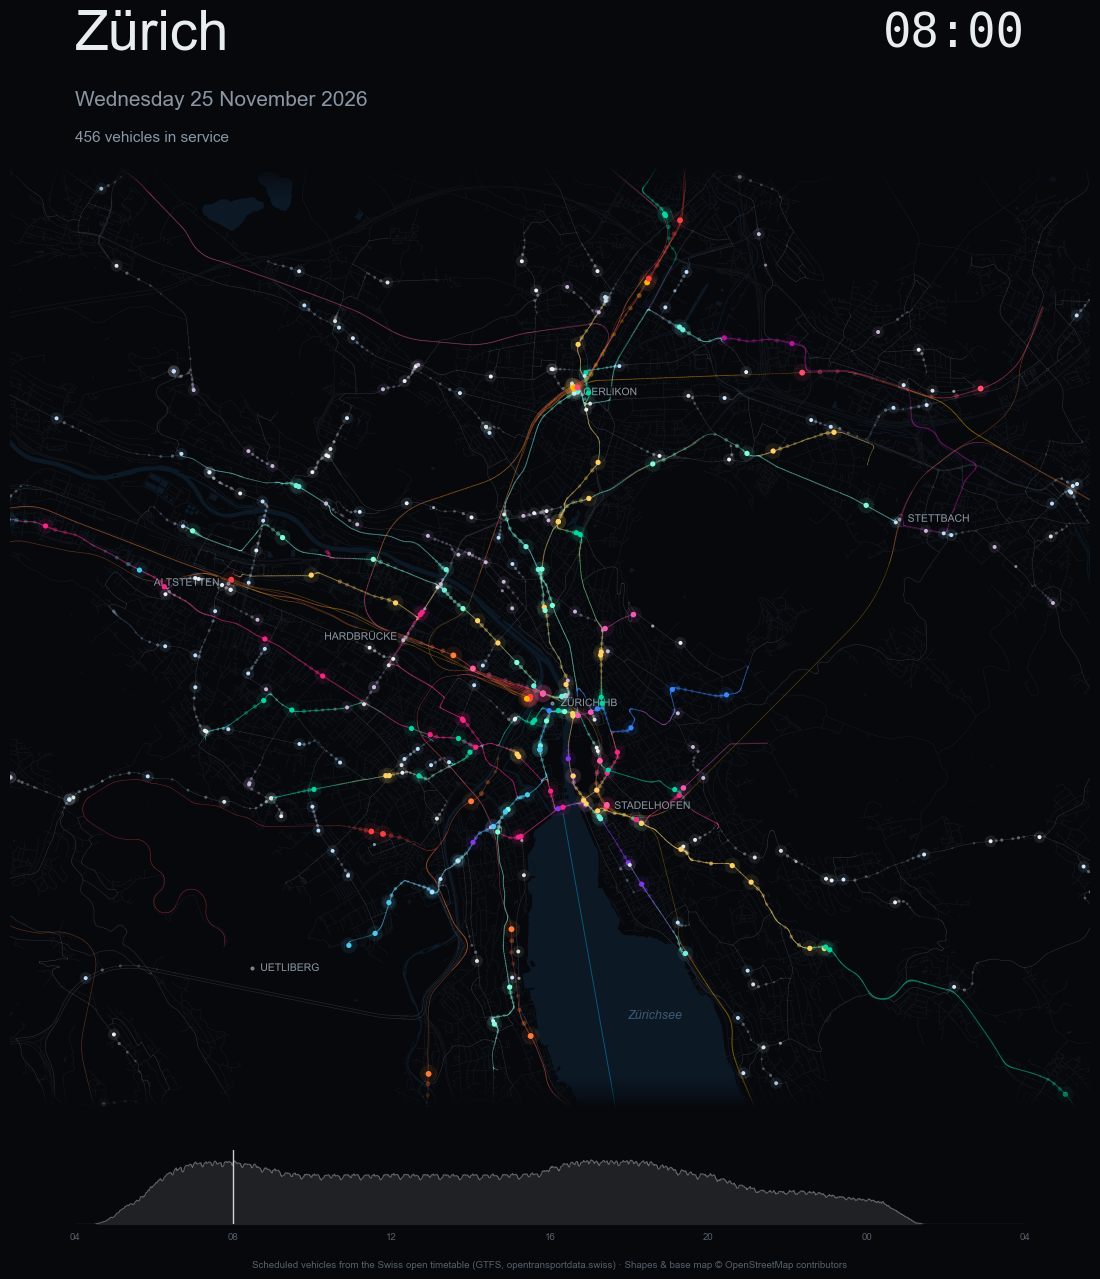

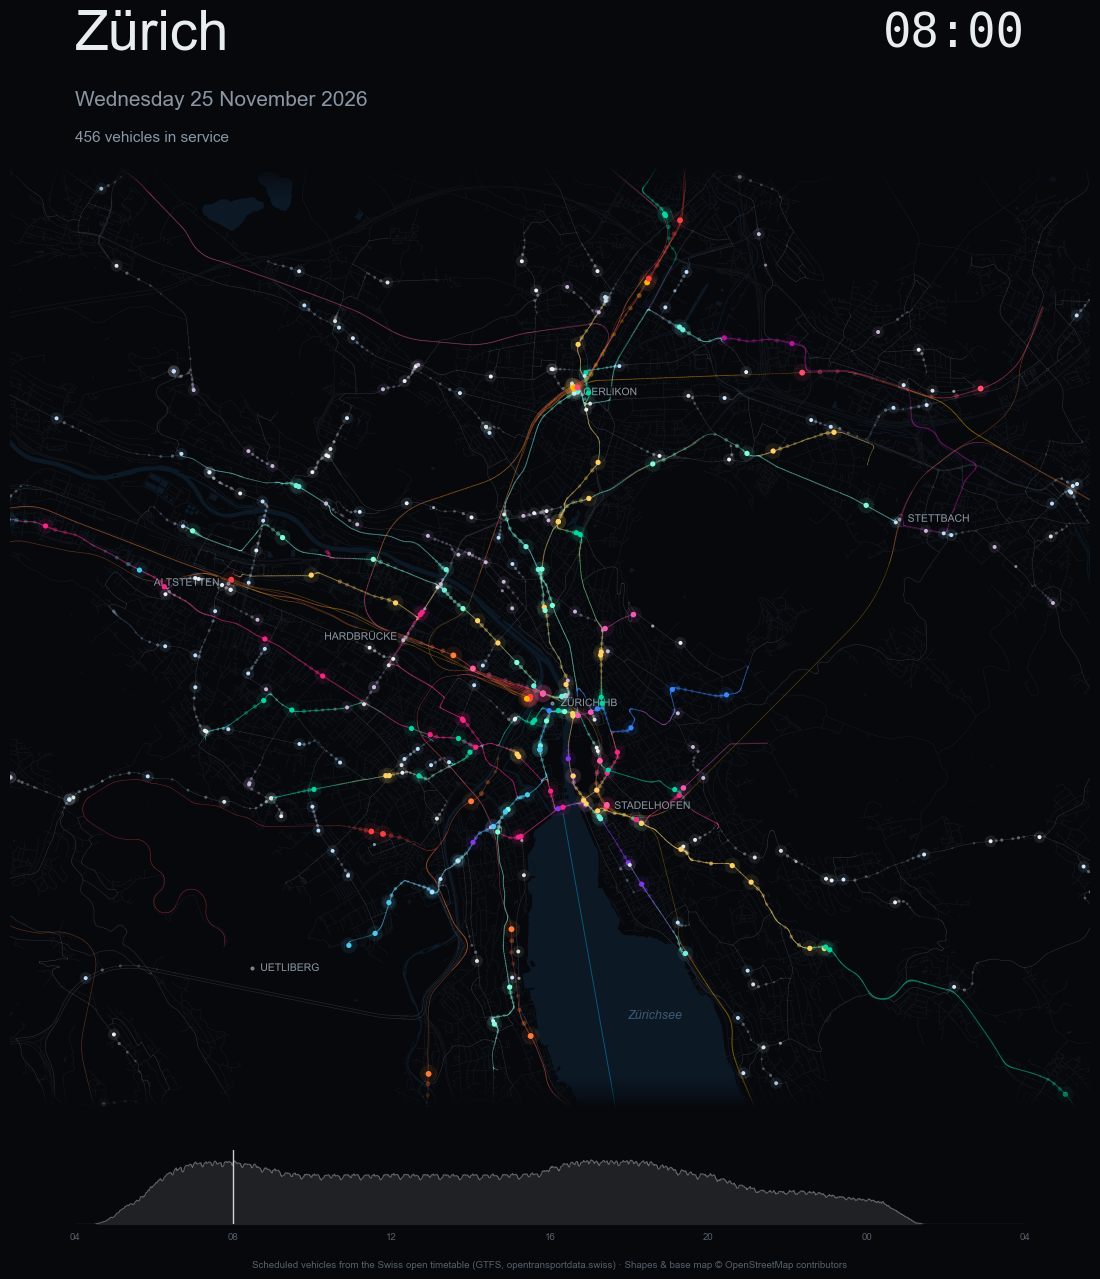

In [90]:
# =============================================================================
# SECTION 11 · Build the figure and preview one frame
# Goal: build everything that stays the same ONCE (water, streets, route lines, labels, text, chart),
#       and define draw(t) to update only what changes (dots, trails, clock, date, count, cursor).
# Layers are stacked by zorder (higher = on top):
#   1 water · 2 streets · 3 route lines · 3.5 labels · 4 glow · 5 trails · 6 dots
# =============================================================================

# --- 1. FONTS: use the first font in FONT that's installed
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = FONT

# --- 2. CANVAS AND MAP PANEL
# Size in inches x dpi = pixels: 1080/100 = 10.8 in wide -> exactly 1080 px.
fig = plt.figure(figsize=(WIDTH_PX / DPI, HEIGHT_PX / DPI), dpi=DPI, facecolor=BG)
# Map panel: [left, bottom, width, height] as fractions of the figure, between the chart band and the title band.
ax = fig.add_axes([0, BOTTOM_BAND, 1, 1 - TOP_BAND - BOTTOM_BAND]); ax.set_facecolor(BG); ax.set_axis_off()
# Show exactly the VIEW rectangle (metres); "equal" = 1 m east is as long on screen as 1 m north.
ax.set_xlim(VIEW[0], VIEW[2]); ax.set_ylim(VIEW[1], VIEW[3]); ax.set_aspect("equal")

# --- 3. BASE LAYERS: water + streets (both optional)
try:
    water = ox.features_from_bbox(DATA_BBOX_LL, tags={"natural": "water"})           # lake, river surfaces
    water = water[water.geom_type.isin(["Polygon", "MultiPolygon"])].to_crs(2056)    # areas only, in Swiss metres
    water.plot(ax=ax, color=WATER, linewidth=0, zorder=1)
except Exception as e:
    print("(no water layer:", type(e).__name__, ")")    # download failed: draw the map without water
if "bus" in NETWORKS:
    net = NETWORKS["bus"]
    # Street background from the bus road network. LineCollection = thousands of lines as one fast object.
    ax.add_collection(LineCollection(net.lines, colors=STREETS, linewidths=0.35, zorder=2))

# --- 4. FAINT ROUTE LINES IN THEIR COLOURS
# Track shared by many lines (e.g. the approach to Zürich HB) is drawn ONCE, in the colour of the
# line that runs most often on it, instead of stacking one translucent line per route.
# Runs per hop and line (busier lines count more):
trips_on = (seg[~seg.dwell].groupby(["gkey", "cidx", "mode"]).key.nunique().rename("trips").reset_index())
ea, eb, ek, ec, ew, em = [], [], [], [], [], []      # per piece of track: point a, point b, network, colour, runs, mode
KIND_CODE = {k: i for i, k in enumerate(NETWORKS)}   # network name -> number
other = []                                           # hops with no network path (boats, funiculars, fallbacks)
for r in trips_on.itertuples(index=False):
    hit = PATHS.get(r.gkey)                          # the hop's network path from Section 8
    if hit is None:
        other.append(r); continue
    kind_, p = hit
    if len(p) < 2: continue
    # Break the path into pieces (neighbouring point pairs), stored smaller-ID first,
    # so the same piece travelled in either direction counts as one.
    ea.append(np.minimum(p[:-1], p[1:])); eb.append(np.maximum(p[:-1], p[1:]))
    n = len(p) - 1
    ek.append(np.full(n, KIND_CODE[kind_])); ec.append(np.full(n, r.cidx)); ew.append(np.full(n, r.trips))
    em.append(np.full(n, r.mode, dtype=object))
segs_bg, cols_bg, lws_bg = [], [], []                # lines, colours, widths to draw
if ea:
    E = pd.DataFrame({"a": np.concatenate(ea), "b": np.concatenate(eb), "k": np.concatenate(ek),
                      "c": np.concatenate(ec), "w": np.concatenate(ew), "m": np.concatenate(em)})
    E = E.groupby(["k", "a", "b", "c", "m"], as_index=False).w.sum()          # total runs per piece and line
    E = E.sort_values("w").drop_duplicates(["k", "a", "b"], keep="last")      # keep the dominant line per piece
    E = E.sort_values("m", key=lambda m: m.map({"bus": 0}).fillna(1))        # buses first = drawn underneath
    kinds_by_code = list(NETWORKS)
    for k_code, grp in E.groupby("k", sort=False):
        xy = NETWORKS[kinds_by_code[k_code]].xy
        segs_bg += list(np.stack([xy[grp.a.values], xy[grp.b.values]], axis=1))       # each piece: line from a to b
        cols_bg += [(*PALETTE[c], ROUTE_ALPHA.get(m, 0.2)) for c, m in zip(grp.c, grp.m)]   # RGB + transparency = RGBA
        lws_bg  += [ROUTE_LW.get(m, 0.6) for m in grp.m]                               # width by mode
for r in other:                                    # straight lines (boats, funiculars, short fallbacks)
    g = GEOM_INDEX[r.gkey]
    if r.gkey in STRAIGHT and r.mode in ROUTED_MODES and np.hypot(*(GEOMS[g][-1] - GEOMS[g][0])) > HIDE_STRAIGHT_OVER_M:
        continue                                   # hide long "as the crow flies" rail/tram/bus lines
    segs_bg.append(GEOMS[g]); cols_bg.append((*PALETTE[r.cidx], ROUTE_ALPHA.get(r.mode, 0.2)))
    lws_bg.append(ROUTE_LW.get(r.mode, 0.6))
# Draw all route lines as one object; round caps so the small pieces join smoothly.
ax.add_collection(LineCollection(segs_bg, colors=cols_bg, linewidths=lws_bg, zorder=3, capstyle="round"))

# --- 5. PLACE LABELS (zorder 3.5: below the moving dots, so vehicles pass over them)
import matplotlib.patheffects as pe
halo_fx = [pe.withStroke(linewidth=2.5, foreground=BG)]   # thin background-coloured outline: keeps text readable over lines
for name, lon, lat, side in PLACE_LABELS:
    x, y = TO_M.transform(lon, lat)                      # label position in metres
    off = {"right": (6, 0), "left": (-6, 0), "center": (0, 0)}[side]   # text offset from the point, in typographic points
    ha  = {"right": "left", "left": "right", "center": "center"}[side] # label on the right = left-aligned text
    ax.plot([x], [y], "o", ms=2, color=LABEL_COLOR, alpha=0.6, zorder=3.5)   # tiny dot at the place
    ax.annotate(name.upper(), (x, y), xytext=off, textcoords="offset points", ha=ha, va="center",
                fontsize=7.5, color=LABEL_COLOR, alpha=0.75, weight="medium", zorder=3.5,
                path_effects=halo_fx, annotation_clip=True)   # clip = hide labels outside the map panel
for name, lon, lat in WATER_LABELS:
    x, y = TO_M.transform(lon, lat)
    ax.text(x, y, name, fontsize=9, style="italic", color="#3d5a73", ha="center", va="center", zorder=3.5)

# --- 6. EMPTY LAYERS FOR THE MOVING DOTS (filled by draw() each frame; updating is faster than recreating)
halo  = ax.scatter([], [], s=[], lw=0, zorder=4)    # big faint circles behind dots = glow
trail = ax.scatter([], [], s=[], lw=0, zorder=5)    # ghost dots = comet trails
core  = ax.scatter([], [], s=[], lw=0, zorder=6)    # the dots themselves

# --- 7. SOFT FADES where the map meets the title and chart bands
# 12 thin background-coloured strips, from nearly solid to transparent = a soft gradient instead of a hard edge.
from matplotlib.patches import Rectangle
N_STRIPS, FADE = 12, 0.025                          # number of strips; fade height (fraction of the figure)
map_top = 1 - TOP_BAND
for k in range(N_STRIPS):
    f = 1 - k / N_STRIPS                            # 1 at the band edge -> 0 towards the map
    h_ = FADE / N_STRIPS
    # transform=fig.transFigure: positions are fractions of the whole figure, not map metres. f**1.5 = gentle curve.
    fig.patches.append(Rectangle((0, map_top - (k + 1) * h_), 1, h_, transform=fig.transFigure,
                                 color=BG, alpha=f ** 1.5, lw=0, zorder=0.5))
    fig.patches.append(Rectangle((0, BOTTOM_BAND + k * h_), 1, h_, transform=fig.transFigure,
                                 color=BG, alpha=f ** 1.5, lw=0, zorder=0.5))

# --- 8. TEXT (positions are fractions of the figure: (0.06, 0.945) = 6% from left, 94.5% up)
fig.text(0.06, 0.945, CITY_NAME, color=TEXT, fontsize=40, va="top", weight="light")
# The ones that change each frame are kept in variables so draw() can update them.
sub   = fig.text(0.06, 0.885, f"{D:%A} {D.day} {D:%B %Y}", color=SUBTEXT, fontsize=15, va="top")   # %A weekday, %B month
clock = fig.text(0.94, 0.945, "", color=TEXT, fontsize=34, va="top", ha="right", family="monospace")  # monospace: digits don't jiggle
count = fig.text(0.06, 0.855, "", color=SUBTEXT, fontsize=11, va="top")
# Credits line (required by the data licences)
fig.text(0.5, 0.012, "Scheduled vehicles from the Swiss open timetable (GTFS, opentransportdata.swiss) · "
         "Shapes & base map © OpenStreetMap contributors",
         color="#55606b", fontsize=7, ha="center", va="bottom")

# --- 9. ACTIVITY CHART along the bottom: vehicles in service over the day (COUNTS from Section 10)
sx = fig.add_axes([0.06, 0.045, 0.88, 0.055]); sx.set_axis_off(); sx.set_zorder(1)   # small axes in the bottom band
hours = FRAME_T / 3600                              # frame times in hours
sx.fill_between(hours, COUNTS, color="#ffffff", alpha=0.10, lw=0)   # soft filled area
sx.plot(hours, COUNTS, color="#ffffff", alpha=0.35, lw=0.8)          # thin line on top
sx.set_xlim(START_H, END_H); sx.set_ylim(0, COUNTS.max() * 1.15)    # 15% headroom above the peak
for hh in range(START_H, END_H + 1, 4):             # hour labels every 4 h: 04 08 12 16 20 00 04
    sx.text(hh, -COUNTS.max() * 0.12, f"{hh % 24:02d}", color="#55606b", fontsize=7, ha="center", va="top")
cursor = sx.axvline(START_H, color="#ffffff", lw=1, alpha=0.8)      # vertical "now" line, moved by draw()

# --- 10. HELPER: colours + transparency for many dots at once (one RGBA row per dot)
def rgba(cidx, alpha):
    c = np.empty((len(cidx), 4)); c[:, :3] = PALETTE[cidx]; c[:, 3] = alpha; return c

# --- 11. DRAW ONE MOMENT: update only what changes
def draw(t, i=None):
    x, y, a = positions_at(t)                       # every vehicle's position now (Section 10)
    # Dots: positions, size by mode, solid colour.
    core.set_offsets(np.c_[x, y]); core.set_sizes(S_SIZE[a]); core.set_facecolor(rgba(S_C[a], 1.0))
    # Glow: same positions, 9x bigger, 9% opaque.
    halo.set_offsets(np.c_[x, y]); halo.set_sizes(S_SIZE[a] * 9); halo.set_facecolor(rgba(S_C[a], 0.09))
    # Comet trails: where every vehicle was 14 s, 28 s, ... ago; older = smaller and fainter.
    tx, ty, ts, tc = [], [], [], []
    for k in range(1, TRAIL_STEPS + 1):
        x2, y2, a2 = positions_at(t - k * TRAIL_DT_S)
        fade = 1 - k / (TRAIL_STEPS + 1)            # 0.83 for the newest ghost down to 0.17 for the oldest
        tx.append(x2); ty.append(y2); ts.append(S_SIZE[a2] * fade * 0.8); tc.append(rgba(S_C[a2], 0.45 * fade))
    if tx:
        trail.set_offsets(np.c_[np.concatenate(tx), np.concatenate(ty)])
        trail.set_sizes(np.concatenate(ts)); trail.set_facecolor(np.vstack(tc))
    # Clock: seconds -> HH:MM, wrapping at 24 h.
    hh, mm = int(t // 3600) % 24, int(t % 3600 // 60)
    clock.set_text(f"{hh:02d}:{mm:02d}")
    # Date: after midnight (t >= 86,400 s) it's the next calendar day.
    day = D + pd.Timedelta(days=int(t // 86400))
    sub.set_text(f"{day:%A} {day.day} {day:%B %Y}")
    count.set_text(f"{len(a):,} vehicles in service")
    cursor.set_xdata([t / 3600, t / 3600])          # move the chart's "now" line

# --- 12. PREVIEW: draw 08:00, save it, and show it in the notebook (check the layout before rendering)
draw(8 * 3600)
fig.savefig(OUT_DIR / "preview_0800.png", dpi=DPI, facecolor=BG)
display(fig)

## 12 · Render the MP4
Encoding uses the ffmpeg binary bundled with `imageio-ffmpeg`, so you don't need to install ffmpeg separately.

In [92]:
import imageio_ffmpeg
from matplotlib.animation import FFMpegWriter

mpl.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
out = OUT_DIR / f"{CITY_NAME.lower().replace('ü', 'ue')}_24h_{SERVICE_DATE}.mp4"
writer = FFMpegWriter(fps=FPS, codec="libx264",
                      extra_args=["-pix_fmt", "yuv420p", "-preset", "veryfast", "-crf", "18"])
with writer.saving(fig, str(out), dpi=DPI):
    for i, t in enumerate(tqdm(FRAME_T, desc="rendering")):
        draw(t, i)
        writer.grab_frame(facecolor=BG)
print("Saved", out.resolve())

rendering:   0%|          | 0/1800 [00:00<?, ?it/s]

Saved D:\Dropbox\Protocol Creative\Protocol30DayMapChallenge2026\Day 24\output\zuerich_24h_2026-11-25.mp4


## 13 · Also export a GIF
GIFs are made from the MP4 with ffmpeg in two passes (build a 256-colour palette first, then use it), which keeps the glow smooth on the dark background.
A full-length, full-size GIF would be huge, so this one is smaller, has fewer frames per second and plays faster. Adjust the three settings to trade size against smoothness.

In [93]:
import subprocess

GIF_WIDTH   = 540     # px (height follows the 4:5 ratio)
GIF_FPS     = 12      # frames per second in the GIF
GIF_SECONDS = 20      # how long the whole 24 h lasts in the GIF (the MP4 lasts VIDEO_SECONDS)

ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()
gif = out.with_suffix(".gif")
speed = VIDEO_SECONDS / GIF_SECONDS
vf = f"setpts=PTS/{speed},fps={GIF_FPS},scale={GIF_WIDTH}:-2:flags=lanczos"
subprocess.run([ffmpeg, "-y", "-v", "error", "-i", str(out), "-vf", f"{vf},palettegen=stats_mode=diff",
                str(OUT_DIR / "palette.png")], check=True)
subprocess.run([ffmpeg, "-y", "-v", "error", "-i", str(out), "-i", str(OUT_DIR / "palette.png"),
                "-lavfi", f"{vf}[x];[x][1:v]paletteuse=dither=bayer:bayer_scale=4:diff_mode=rectangle",
                "-loop", "0", str(gif)], check=True)
print(f"Saved {gif.resolve()}  ({gif.stat().st_size / 1e6:.1f} MB)")

Saved D:\Dropbox\Protocol Creative\Protocol30DayMapChallenge2026\Day 24\output\zuerich_24h_2026-11-25.gif  (17.8 MB)


## 14 · Ideas for tweaking
- **Busiest-minute still:** call `draw(peak)` and then `fig.savefig("output/peak.png", dpi=300)` for a poster version.
- **Night network:** set `SERVICE_DATE` to a Friday. Zürich's night lines only run on Friday and Saturday nights.
- **Slower and smoother:** use `VIDEO_SECONDS = 90` and `FPS = 30`. For Reels or Shorts, use `WIDTH_PX, HEIGHT_PX = 1080, 1920`.
- **Exact line colours:** fill `ROUTE_COLOR_OVERRIDES`, for example `{"tram:2": "#…", "rail:S5": "#…"}`.
- **Another Swiss city:** change `CITY_NAME` and `DISPLAY_BBOX`. Bern, Basel, Geneva and Lausanne all work with the same feed.
- **Another country:** point `GTFS_URL` at any GTFS zip (find one on mobilitydatabase.org). If that feed has `shapes.txt`, you can still keep the OSM routing here.